## About Dataset
Context
This is a small subset of dataset of Book reviews from Amazon Kindle Store category.

Content
5-core dataset of product reviews from Amazon Kindle Store category from May 1996 - July 2014. Contains total of 982619 entries. Each reviewer has at least 5 reviews and each product has at least 5 reviews in this dataset.
Columns

- asin - ID of the product, like B000FA64PK
- helpful - helpfulness rating of the review - example: 2/3.
- overall - rating of the product.
- reviewText - text of the review (heading).
- reviewTime - time of the review (raw).
- reviewerID - ID of the reviewer, like A3SPTOKDG7WBLN
- reviewerName - name of the reviewer.
- summary - summary of the review (description).
- unixReviewTime - unix timestamp.

Acknowledgements
This dataset is taken from Amazon product data, Julian McAuley, UCSD website. http://jmcauley.ucsd.edu/data/amazon/

License to the data files belong to them.

Inspiration
- Sentiment analysis on reviews.
- Understanding how people rate usefulness of a review/ What factors influence helpfulness of a review.
- Fake reviews/ outliers.
- Best rated product IDs, or similarity between products based on reviews alone (not the best idea ikr).
- Any other interesting analysis

#### Best Practises
1. Preprocessing And Cleaning (Feature Engineering)
2. Train Test Split
3. BOW,TFIDF,Word2vec
4. Train ML algorithms

In [1]:
# Load the dataset
import pandas as pd
data=pd.read_csv('all_kindle_review.csv')
data.head()

,Unnamed: 0.1,Unnamed: 0,asin,helpful,rating,reviewText,reviewTime,reviewerID,reviewerName,summary,unixReviewTime
0,0,11539,B0033UV8HI,"[8, 10]",3,"Jace Rankin may be short, but he's nothing to ...","09 2, 2010",A3HHXRELK8BHQG,Ridley,Entertaining But Average,1283385600
1,1,5957,B002HJV4DE,"[1, 1]",5,Great short read. I didn't want to put it dow...,"10 8, 2013",A2RGNZ0TRF578I,Holly Butler,Terrific menage scenes!,1381190400
2,2,9146,B002ZG96I4,"[0, 0]",3,I'll start by saying this is the first of four...,"04 11, 2014",A3S0H2HV6U1I7F,Merissa,Snapdragon Alley,1397174400
3,3,7038,B002QHWOEU,"[1, 3]",3,Aggie is Angela Lansbury who carries pocketboo...,"07 5, 2014",AC4OQW3GZ919J,Cleargrace,very light murder cozy,1404518400
4,4,1776,B001A06VJ8,"[0, 1]",4,I did not expect this type of book to be in li...,"12 31, 2012",A3C9V987IQHOQD,Rjostler,Book,1356912000


In [2]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Unnamed: 0.1    12000 non-null  int64 
 1   Unnamed: 0      12000 non-null  int64 
 2   asin            12000 non-null  object
 3   helpful         12000 non-null  object
 4   rating          12000 non-null  int64 
 5   reviewText      12000 non-null  object
 6   reviewTime      12000 non-null  object
 7   reviewerID      12000 non-null  object
 8   reviewerName    11962 non-null  object
 9   summary         11998 non-null  object
 10  unixReviewTime  12000 non-null  int64 
dtypes: int64(4), object(7)
memory usage: 1.0+ MB


In [3]:
df=data[['reviewText','rating']]
df.head()

,reviewText,rating
0,"Jace Rankin may be short, but he's nothing to ...",3
1,Great short read. I didn't want to put it dow...,5
2,I'll start by saying this is the first of four...,3
3,Aggie is Angela Lansbury who carries pocketboo...,3
4,I did not expect this type of book to be in li...,4


In [4]:
df.shape

(12000, 2)

In [5]:
## Missing Values
df.isnull().sum()

,0
reviewText,0
rating,0


In [6]:
df['rating'].unique()

array([3, 5, 4, 2, 1])

In [7]:
df['rating'].value_counts()

,count
rating,
5,3000
4,3000
3,2000
2,2000
1,2000


## Preprocessing And Cleaning

In [8]:
## postive review is 1 and negative review is 0
df['rating']=df['rating'].apply(lambda x:0 if x<3 else 1)

/tmp/ipykernel_1469/3208188810.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['rating']=df['rating'].apply(lambda x:0 if x<3 else 1)


In [9]:
df['rating'].value_counts()

,count
rating,
1,8000
0,4000


In [10]:
## 1. Lower All the cases
df['reviewText']=df['reviewText'].str.lower()

/tmp/ipykernel_1469/1654308119.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['reviewText']=df['reviewText'].str.lower()


In [11]:
df.head()

,reviewText,rating
0,"jace rankin may be short, but he's nothing to ...",1
1,great short read. i didn't want to put it dow...,1
2,i'll start by saying this is the first of four...,1
3,aggie is angela lansbury who carries pocketboo...,1
4,i did not expect this type of book to be in li...,1


In [12]:
import re
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [13]:
df['rating'].value_counts()

,count
rating,
1,8000
0,4000


In [14]:
%pip install beautifulsoup4

In [15]:
from bs4 import BeautifulSoup

In [16]:
## Removing special characters
df['reviewText']=df['reviewText'].apply(lambda x:re.sub('[^a-z A-z 0-9-]+', '',x))
## Remove the stopswords
df['reviewText']=df['reviewText'].apply(lambda x:" ".join([y for y in x.split() if y not in stopwords.words('english')]))
## Remove url
df['reviewText']=df['reviewText'].apply(lambda x: re.sub(r'(http|https|ftp|ssh)://([\w_-]+(?:(?:\.[\w_-]+)+))([\w.,@?^=%&:/~+#-]*[\w@?^=%&/~+#-])?', '' , str(x)))
## Remove html tags
df['reviewText']=df['reviewText'].apply(lambda x: BeautifulSoup(x, 'lxml').get_text())
## Remove any additional spaces
df['reviewText']=df['reviewText'].apply(lambda x: " ".join(x.split()))


/tmp/ipykernel_1469/1198541269.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['reviewText']=df['reviewText'].apply(lambda x:re.sub('[^a-z A-z 0-9-]+', '',x))
/tmp/ipykernel_1469/1198541269.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['reviewText']=df['reviewText'].apply(lambda x:" ".join([y for y in x.split() if y not in stopwords.words('english')]))
/tmp/ipykernel_1469/1198541269.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .l

In [17]:
df.head()

,reviewText,rating
0,jace rankin may short hes nothing mess man hau...,1
1,great short read didnt want put read one sitti...,1
2,ill start saying first four books wasnt expect...,1
3,aggie angela lansbury carries pocketbooks inst...,1
4,expect type book library pleased find price right,1


In [18]:
## Lemmatizer
from nltk.stem import WordNetLemmatizer

In [19]:
lemmatizer=WordNetLemmatizer()

In [20]:
def lemmatize_words(text):
    return " ".join([lemmatizer.lemmatize(word) for word in text.split()])


In [21]:
import nltk
nltk.download('wordnet')
df['reviewText']=df['reviewText'].apply(lambda x:lemmatize_words(x))

[nltk_data] Downloading package wordnet to /root/nltk_data...
/tmp/ipykernel_1469/137616133.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['reviewText']=df['reviewText'].apply(lambda x:lemmatize_words(x))


In [22]:
df.head()

,reviewText,rating
0,jace rankin may short he nothing mess man haul...,1
1,great short read didnt want put read one sitti...,1
2,ill start saying first four book wasnt expecti...,1
3,aggie angela lansbury carry pocketbook instead...,1
4,expect type book library pleased find price right,1


## Train - Test Split

In [23]:
## Train Test Split
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(df['reviewText'],df['rating'],
                                              test_size=0.20,random_state=42)

# BOW

In [24]:
from sklearn.feature_extraction.text import CountVectorizer
cv=CountVectorizer()
X_train_bow=cv.fit_transform(X_train)
X_test_bow=cv.transform(X_test)

In [25]:
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000,
    formatter=dict(float=lambda x: "%.3g" % x))
X_train_bow

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 432286 stored elements and shape (9600, 35736)>

In [26]:
from sklearn.naive_bayes import MultinomialNB, BernoulliNB, ComplementNB

from sklearn.linear_model import LogisticRegression

from sklearn.svm import LinearSVC

from sklearn.ensemble import RandomForestClassifier

from sklearn.tree import DecisionTreeClassifier

from sklearn.neighbors import KNeighborsClassifier

In [27]:
models = {
    'MultinomialNB': MultinomialNB(),
    'BernoulliNB': BernoulliNB(),
    'ComplementNB': ComplementNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'SVM': LinearSVC(),
    'Random Forest': RandomForestClassifier(),
    'Decision Tree': DecisionTreeClassifier(),
    'KNN': KNeighborsClassifier()
}

results = {}

for name, model in models.items():

    model.fit(X_train_bow, y_train)

    y_pred = model.predict(X_test_bow)

    results[name] = y_pred

    print(f"{name} trained successfully")

MultinomialNB trained successfully
BernoulliNB trained successfully
ComplementNB trained successfully
Logistic Regression trained successfully
SVM trained successfully
Random Forest trained successfully
Decision Tree trained successfully
KNN trained successfully


In [28]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

model_results = []

for name, model in models.items():

    model.fit(X_train_bow, y_train)

    y_pred = model.predict(X_test_bow)

    model_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred)
    })

results_df = pd.DataFrame(model_results)

results_df = results_df.sort_values(
    by='F1 Score',
    ascending=False
)

display(results_df)

## save BOW results under its own name
bow_results = results_df.copy()

,Model,Accuracy,Precision,Recall,F1 Score
0,MultinomialNB,0.838750,0.849307,0.921102,0.883749
3,Logistic Regression,0.837500,0.861161,0.901064,0.880661
2,ComplementNB,0.837500,0.867316,0.892298,0.879630
5,Random Forest,0.796667,0.781044,0.964934,0.863305
1,BernoulliNB,0.795833,0.786047,0.952411,0.861268
4,SVM,0.808333,0.849416,0.865373,0.857320
6,Decision Tree,0.721667,0.779314,0.811522,0.795092
7,KNN,0.678750,0.700291,0.904195,0.789287


In [29]:
best_model_name = results_df.iloc[0]['Model']
best_model = models[best_model_name]

print("Best Model:", best_model_name)
print("Best F1 Score:", results_df.iloc[0]['F1 Score'])

Best Model: MultinomialNB
Best F1 Score: 0.8837488735355963


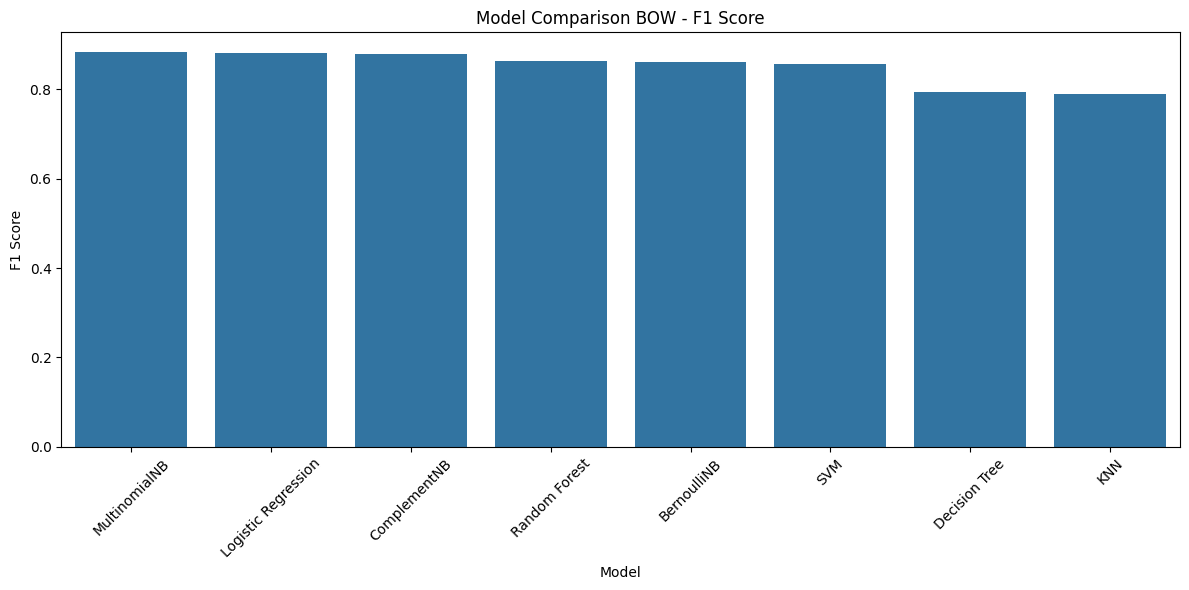

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='F1 Score'
)

plt.xticks(rotation=45)
plt.title('Model Comparison BOW - F1 Score')
plt.tight_layout()
plt.show()

# TF-IDF

In [31]:
## Train Test Split
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(df['reviewText'],df['rating'],
                                              test_size=0.20,random_state=42)

In [32]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf=TfidfVectorizer()
X_train_tfidf=tfidf.fit_transform(X_train)
X_test_tfidf=tfidf.transform(X_test)

In [33]:
models = {
    'MultinomialNB': MultinomialNB(),
    'BernoulliNB': BernoulliNB(),
    'ComplementNB': ComplementNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'SVM': LinearSVC(),
    'Random Forest': RandomForestClassifier(),
    'Decision Tree': DecisionTreeClassifier(),
    'KNN': KNeighborsClassifier()
}

results = {}

for name, model in models.items():

    model.fit(X_train_tfidf, y_train)

    y_pred = model.predict(X_test_tfidf)

    results[name] = y_pred

    print(f"{name} trained successfully")

MultinomialNB trained successfully
BernoulliNB trained successfully
ComplementNB trained successfully
Logistic Regression trained successfully
SVM trained successfully
Random Forest trained successfully
Decision Tree trained successfully
KNN trained successfully


In [34]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

model_results = []

for name, model in models.items():

    model.fit(X_train_tfidf, y_train)

    y_pred = model.predict(X_test_tfidf)

    model_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred)
    })

results_df = pd.DataFrame(model_results)

results_df = results_df.sort_values(
    by='F1 Score',
    ascending=False
)

display(results_df)

## save TF-IDF results under its own name
tfidf_results = results_df.copy()

,Model,Accuracy,Precision,Recall,F1 Score
3,Logistic Regression,0.843750,0.840960,0.943644,0.889348
4,SVM,0.841667,0.859421,0.911083,0.884498
5,Random Forest,0.795833,0.780537,0.964308,0.862745
1,BernoulliNB,0.795833,0.786047,0.952411,0.861268
2,ComplementNB,0.749583,0.729917,0.989981,0.840287
7,KNN,0.767917,0.780172,0.906700,0.838691
0,MultinomialNB,0.693750,0.684979,0.999374,0.812834
6,Decision Tree,0.715000,0.781616,0.793363,0.787446


In [35]:
best_model_name = results_df.iloc[0]['Model']
best_model = models[best_model_name]

print("Best Model:", best_model_name)
print("Best F1 Score:", results_df.iloc[0]['F1 Score'])

Best Model: Logistic Regression
Best F1 Score: 0.8893478902331071


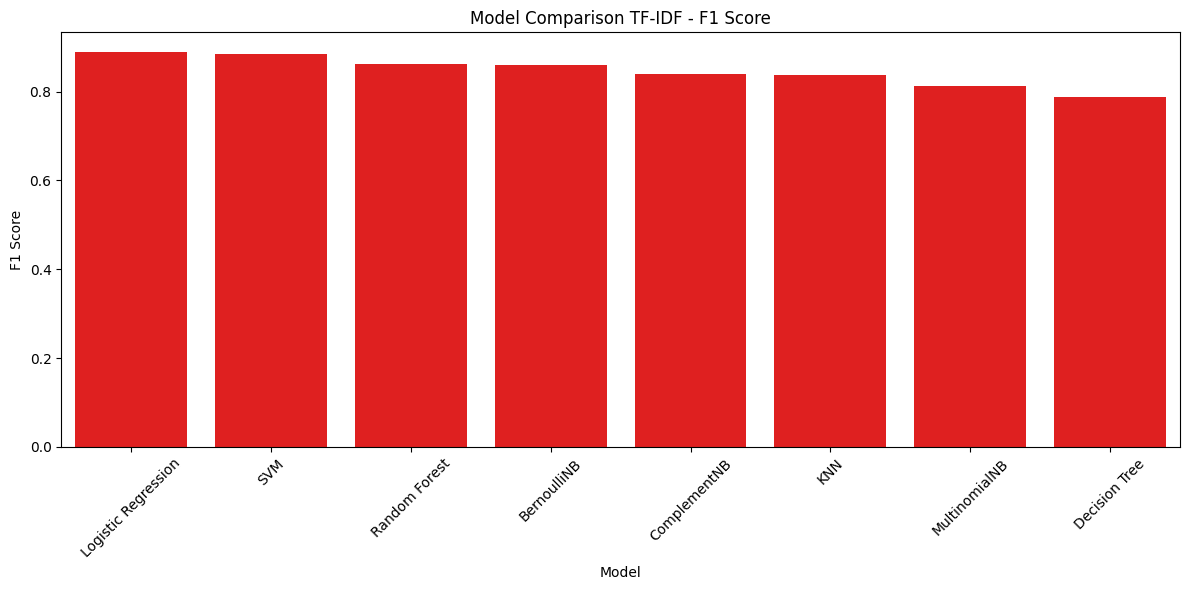

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='F1 Score',
    color="red"
)

plt.xticks(rotation=45)
plt.title('Model Comparison TF-IDF - F1 Score')
plt.tight_layout()
plt.show()

# Word2Vec

In [37]:
%pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 64.6 MB/s  0:00:00


In [38]:
import gensim
from gensim.models import Word2Vec, KeyedVectors

In [39]:
import gensim.downloader as api

wv = api.load('word2vec-google-news-300')

vec_king = wv['king']

[==================================================] 100.0% 1662.8/1662.8MB downloaded


In [40]:
vec_king

array([0.126, 0.0298, 0.00861, 0.14, -0.0256, -0.0361, 0.112, -0.198, 0.0513, 0.363, -0.242, -0.303, -0.178, -0.0249, -0.168, -0.17, 0.0347, 0.00522, 0.0464, 0.129, 0.137, 0.113, 0.0596, 0.137, 0.101, -0.177, -0.252, 0.0598, 0.342, -0.0311, 0.104, 0.0618, 0.125, 0.4, -0.322, 0.084, 0.0391, 0.00586, 0.0703, 0.173, 0.139, -0.231, 0.283, 0.143, 0.342, -0.0239, -0.11, 0.0332, -0.0547, 0.0153, -0.162, 0.158, -0.26, 0.0201, -0.163, 0.00136, -0.145, -0.0569, 0.043, -0.0247, 0.186, 0.447, 0.00958, 0.132, 0.0986, -0.186, -0.1, -0.134, -0.125, 0.283, 0.123, 0.0532, -0.178, 0.0859, -0.0219, 0.0205, -0.14, 0.0251, 0.139, -0.105, 0.139, 0.0889, -0.0752, -0.0214, 0.173, 0.0464, -0.266, 0.00891, 0.149, 0.0378, 0.238, -0.125, -0.218, -0.182, 0.0298, 0.0571, -0.0289, 0.0125, 0.0967, -0.231, 0.0581, 0.0669, 0.0708, -0.309, -0.215, 0.146, -0.428, -0.0094, 0.154, -0.0767, 0.289, 0.277, -0.000486, -0.137, 0.324, -0.246, -0.00304, -0.212, 0.125, 0.27, 0.204, 0.0825, -0.201, -0.16, -0.0378, -0.12, 0.115, -0.

In [41]:
vec_king.shape

(300,)

In [42]:
from nltk import sent_tokenize
from gensim.utils import simple_preprocess

In [43]:
words=[]
for sent in df['reviewText'].values:
        words.append(simple_preprocess(sent))

In [44]:
words

[['jace',
  'rankin',
  'may',
  'short',
  'he',
  'nothing',
  'mess',
  'man',
  'hauled',
  'saloon',
  'undertaker',
  'know',
  'he',
  'famous',
  'bounty',
  'hunter',
  'oregon',
  'shot',
  'man',
  'saloon',
  'finished',
  'year',
  'long',
  'quest',
  'avenge',
  'sister',
  'murder',
  'trying',
  'figure',
  'next',
  'snotty',
  'nosed',
  'farm',
  'boy',
  'rescued',
  'gang',
  'bully',
  'offer',
  'money',
  'kill',
  'man',
  'forced',
  'ranch',
  'reluctantly',
  'agrees',
  'bring',
  'man',
  'justice',
  'kill',
  'outright',
  'first',
  'need',
  'tell',
  'sister',
  'widower',
  'newskyla',
  'kyle',
  'springer',
  'bailey',
  'riding',
  'trail',
  'sleeping',
  'ground',
  'past',
  'month',
  'trying',
  'find',
  'jace',
  'want',
  'revenge',
  'man',
  'killed',
  'husband',
  'took',
  'ranch',
  'amongst',
  'crime',
  'shes',
  'keen',
  'detour',
  'jace',
  'want',
  'take',
  'realizes',
  'shes',
  'option',
  'hide',
  'behind',
  'boy',
 

In [45]:
import gensim

In [46]:
## Lets train Word2vec from scratch
model=gensim.models.Word2Vec(words,epochs=200)

In [47]:
model.corpus_count

12000

In [48]:
## To Get All the Vocabulary
model.wv.index_to_key

['book',
 'story',
 'read',
 'one',
 'character',
 'like',
 'good',
 'would',
 'really',
 'love',
 'time',
 'get',
 'author',
 'reading',
 'series',
 'well',
 'much',
 'first',
 'even',
 'didnt',
 'short',
 'know',
 'way',
 'great',
 'could',
 'make',
 'sex',
 'little',
 'dont',
 'two',
 'thing',
 'want',
 'think',
 'find',
 'plot',
 'romance',
 'also',
 'end',
 'life',
 'im',
 'see',
 'enjoyed',
 'go',
 'scene',
 'never',
 'written',
 'take',
 'woman',
 'many',
 'lot',
 'kindle',
 'year',
 'say',
 'thought',
 'work',
 'bit',
 'found',
 'going',
 'give',
 'interesting',
 'liked',
 'writing',
 'novel',
 'loved',
 'another',
 'feel',
 'better',
 'got',
 'come',
 'man',
 'hot',
 'still',
 'back',
 'enough',
 'though',
 'people',
 'star',
 'reader',
 'made',
 'something',
 'review',
 'part',
 'friend',
 'page',
 'cant',
 'bad',
 'world',
 'need',
 'free',
 'new',
 'keep',
 'wasnt',
 'doesnt',
 'relationship',
 'enjoy',
 'recommend',
 'together',
 'next',
 'start',
 'felt',
 'best',
 'put',

In [49]:
model.epochs

200

In [50]:
model.wv.similar_by_word('good')

[('great', 0.7464859485626221),
 ('decent', 0.659964919090271),
 ('interesting', 0.5660311579704285),
 ('nice', 0.5431162118911743),
 ('much', 0.5213168859481812),
 ('story', 0.5156315565109253),
 ('better', 0.5071802735328674),
 ('like', 0.4926246702671051),
 ('short', 0.4911402463912964),
 ('lot', 0.4876531660556793)]

In [51]:
model.wv['man'].shape

(100,)

In [52]:
def avg_word2vec(doc):
    # remove out-of-vocabulary words
    vecs = [model.wv[word] for word in doc if word in model.wv.key_to_index]
    # return zeros (not NaN) when no word of the doc is in the vocabulary
    return np.mean(vecs, axis=0) if len(vecs) > 0 else np.zeros(model.vector_size)

In [53]:
!pip install tqdm

In [54]:
from tqdm import tqdm

In [55]:
#apply for the entire sentences
import numpy as np
X=[]
for i in tqdm(range(len(words))):
    X.append(avg_word2vec(words[i]))

100%|██████████| 12000/12000 [00:01<00:00, 9083.17it/s]


In [56]:
len(X)

12000

In [57]:
X_new=np.array(X)

In [58]:
X_new.shape

(12000, 100)

In [59]:
y = df['rating']

In [60]:
y.shape

(12000,)

In [61]:
X[0].reshape(1,-1).shape

(1, 100)

In [62]:
## this is the final independent features
df=pd.DataFrame(X)

In [63]:
df.head()

,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
0,0.119943,-0.007574,-0.020533,-0.052303,-0.472759,0.392509,0.084182,-0.578126,0.105745,0.110558,...,-0.238622,0.078626,-0.274684,-0.053536,0.210263,0.353392,-0.304855,0.042219,0.460395,0.041685
1,0.729372,-0.364411,-0.797959,-0.625556,-0.160461,0.842374,-0.674209,-0.459308,0.485295,0.310391,...,-1.385150,-0.721238,-0.324073,-0.347681,-1.039865,1.398732,0.570835,0.200104,0.824507,0.440283
2,-0.095448,-0.250946,-0.282909,-0.656819,-0.167621,0.300165,-0.133810,-0.043626,-0.131141,0.082628,...,-0.857849,-0.321524,0.018184,-0.401585,-0.439719,-0.103779,0.523674,0.050085,0.192144,0.507342
3,0.058310,-0.693337,-0.739682,-0.896131,-0.228150,-0.036781,0.513447,0.143492,0.031931,0.484432,...,-0.907206,-0.517767,0.266134,-1.115707,-1.415345,0.154998,1.062770,-0.216193,0.158852,0.449303
4,1.056836,0.388859,-0.121433,-0.955292,-0.371319,0.714543,-0.728007,1.011329,2.371415,0.247662,...,-1.288843,0.041549,1.240737,-0.959411,-1.305213,0.405393,0.485213,1.119764,0.228979,0.535863


In [64]:
df['Output']=y

In [65]:
df.head()

,0,1,2,3,4,5,6,7,8,9,...,91,92,93,94,95,96,97,98,99,Output
0,0.119943,-0.007574,-0.020533,-0.052303,-0.472759,0.392509,0.084182,-0.578126,0.105745,0.110558,...,0.078626,-0.274684,-0.053536,0.210263,0.353392,-0.304855,0.042219,0.460395,0.041685,1
1,0.729372,-0.364411,-0.797959,-0.625556,-0.160461,0.842374,-0.674209,-0.459308,0.485295,0.310391,...,-0.721238,-0.324073,-0.347681,-1.039865,1.398732,0.570835,0.200104,0.824507,0.440283,1
2,-0.095448,-0.250946,-0.282909,-0.656819,-0.167621,0.300165,-0.133810,-0.043626,-0.131141,0.082628,...,-0.321524,0.018184,-0.401585,-0.439719,-0.103779,0.523674,0.050085,0.192144,0.507342,1
3,0.058310,-0.693337,-0.739682,-0.896131,-0.228150,-0.036781,0.513447,0.143492,0.031931,0.484432,...,-0.517767,0.266134,-1.115707,-1.415345,0.154998,1.062770,-0.216193,0.158852,0.449303,1
4,1.056836,0.388859,-0.121433,-0.955292,-0.371319,0.714543,-0.728007,1.011329,2.371415,0.247662,...,0.041549,1.240737,-0.959411,-1.305213,0.405393,0.485213,1.119764,0.228979,0.535863,1


In [66]:
df.dropna(inplace=True)

In [67]:
df.isnull().sum()

,0
0,0
1,0
2,0
3,0
4,0
...,...
96,0
97,0
98,0
99,0


In [68]:
## Independent Feature
X=df.drop('Output',axis=1)

In [69]:
y=df['Output']

In [70]:
## Train Test Split
from sklearn.model_selection import train_test_split
X_train_w2v,X_test_w2v,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42)

In [71]:
from sklearn.naive_bayes import MultinomialNB, BernoulliNB, ComplementNB

from sklearn.linear_model import LogisticRegression

from sklearn.svm import LinearSVC

from sklearn.ensemble import RandomForestClassifier

from sklearn.tree import DecisionTreeClassifier

from sklearn.neighbors import KNeighborsClassifier

In [72]:
models = {
    'BernoulliNB': BernoulliNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'SVM': LinearSVC(),
    'Random Forest': RandomForestClassifier(),
    'Decision Tree': DecisionTreeClassifier(),
    'KNN': KNeighborsClassifier()
}

results = {}

for name, model in models.items():

    model.fit(X_train_w2v, y_train)

    y_pred = model.predict(X_test_w2v)

    results[name] = y_pred

    print(f"{name} trained successfully")

BernoulliNB trained successfully
Logistic Regression trained successfully
SVM trained successfully
Random Forest trained successfully
Decision Tree trained successfully
KNN trained successfully


In [73]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

model_results = []

for name, model in models.items():

    model.fit(X_train_w2v, y_train)

    y_pred = model.predict(X_test_w2v)

    model_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred)
    })

results_df = pd.DataFrame(model_results)

results_df = results_df.sort_values(
    by='F1 Score',
    ascending=False
)

display(results_df)

## save Word2Vec results under its own name
w2v_results = results_df.copy()

,Model,Accuracy,Precision,Recall,F1 Score
2,SVM,0.832083,0.849941,0.907952,0.877990
1,Logistic Regression,0.832083,0.851176,0.906074,0.877768
3,Random Forest,0.808750,0.816463,0.919224,0.864801
5,KNN,0.802500,0.818491,0.903569,0.858929
0,BernoulliNB,0.762917,0.862482,0.765811,0.811277
4,Decision Tree,0.702917,0.774534,0.780839,0.777674


In [74]:
best_model_name = results_df.iloc[0]['Model']
best_model = models[best_model_name]

print("Best Model:", best_model_name)
print("Best F1 Score:", results_df.iloc[0]['F1 Score'])

Best Model: SVM
Best F1 Score: 0.877989706327581


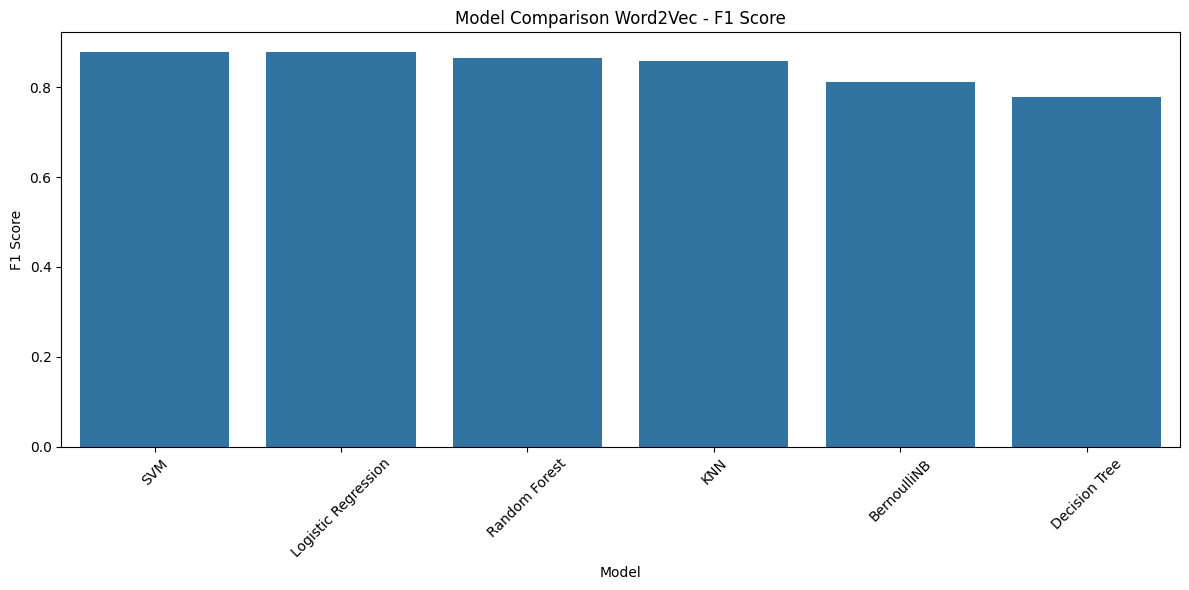

In [75]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x='Model',
    y='F1 Score'
)

plt.xticks(rotation=45)
plt.title('Model Comparison Word2Vec - F1 Score')
plt.tight_layout()
plt.show()

# Benchmark: BOW vs TF-IDF vs Word2Vec

In [76]:
## Cell 1: all models, grouped by BOW / TF-IDF / Word2Vec
bow_df   = bow_results.copy();   bow_df['Features']   = 'BOW'
tfidf_df = tfidf_results.copy(); tfidf_df['Features'] = 'TF-IDF'
w2v_df   = w2v_results.copy();   w2v_df['Features']   = 'Word2Vec'

all_results = pd.concat([bow_df, tfidf_df, w2v_df], ignore_index=True)
all_results = all_results[['Features', 'Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score']]

# BOW first, then TF-IDF, then Word2Vec; best F1 first inside each group
order = {'BOW': 0, 'TF-IDF': 1, 'Word2Vec': 2}
all_results['order'] = all_results['Features'].map(order)
all_results = all_results.sort_values(['order', 'F1 Score'], ascending=[True, False]).drop(columns='order').reset_index(drop=True)

print("=== All models grouped by BOW, TF-IDF, Word2Vec ===")
display(all_results.round(4))

print("\n=== F1 Score: model vs feature type ===")
display(all_results.pivot(index='Model', columns='Features', values='F1 Score').round(4))

=== All models grouped by BOW, TF-IDF, Word2Vec ===


,Features,Model,Accuracy,Precision,Recall,F1 Score
0,BOW,MultinomialNB,0.8388,0.8493,0.9211,0.8837
1,BOW,Logistic Regression,0.8375,0.8612,0.9011,0.8807
2,BOW,ComplementNB,0.8375,0.8673,0.8923,0.8796
3,BOW,Random Forest,0.7967,0.7810,0.9649,0.8633
4,BOW,BernoulliNB,0.7958,0.7860,0.9524,0.8613
5,BOW,SVM,0.8083,0.8494,0.8654,0.8573
6,BOW,Decision Tree,0.7217,0.7793,0.8115,0.7951
7,BOW,KNN,0.6788,0.7003,0.9042,0.7893
8,TF-IDF,Logistic Regression,0.8438,0.8410,0.9436,0.8893
9,TF-IDF,SVM,0.8417,0.8594,0.9111,0.8845



=== F1 Score: model vs feature type ===


Features,BOW,TF-IDF,Word2Vec
Model,,,
BernoulliNB,0.8613,0.8613,0.8113
ComplementNB,0.8796,0.8403,NaN
Decision Tree,0.7951,0.7874,0.7777
KNN,0.7893,0.8387,0.8589
Logistic Regression,0.8807,0.8893,0.8778
MultinomialNB,0.8837,0.8128,NaN
Random Forest,0.8633,0.8627,0.8648
SVM,0.8573,0.8845,0.8780


In [77]:
## Cell 2: top 10 models between BOW, TF-IDF and Word2Vec
top10 = all_results.sort_values('F1 Score', ascending=False).head(10).reset_index(drop=True)
top10.index = top10.index + 1
top10.index.name = 'Rank'

print("=== Top 10 models ===")
display(top10.round(4))

best = top10.iloc[0]
print(f"\nOverall best: {best['Model']} with {best['Features']} (F1 = {best['F1 Score']:.4f})")

=== Top 10 models ===


,Features,Model,Accuracy,Precision,Recall,F1 Score
Rank,,,,,,
1,TF-IDF,Logistic Regression,0.8438,0.8410,0.9436,0.8893
2,TF-IDF,SVM,0.8417,0.8594,0.9111,0.8845
3,BOW,MultinomialNB,0.8388,0.8493,0.9211,0.8837
4,BOW,Logistic Regression,0.8375,0.8612,0.9011,0.8807
5,BOW,ComplementNB,0.8375,0.8673,0.8923,0.8796
6,Word2Vec,SVM,0.8321,0.8499,0.9080,0.8780
7,Word2Vec,Logistic Regression,0.8321,0.8512,0.9061,0.8778
8,Word2Vec,Random Forest,0.8088,0.8165,0.9192,0.8648
9,BOW,Random Forest,0.7967,0.7810,0.9649,0.8633



Overall best: Logistic Regression with TF-IDF (F1 = 0.8893)


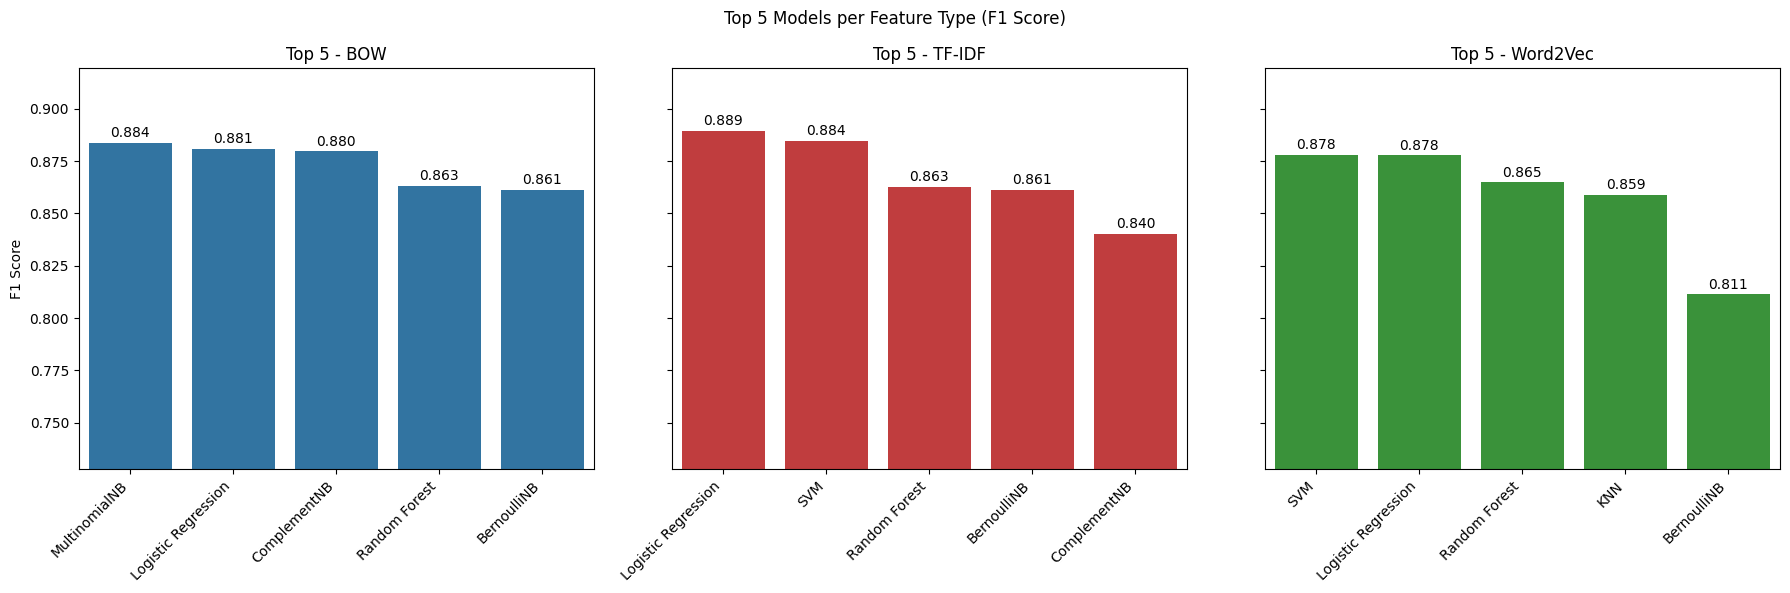

In [78]:
## Cell 3: bar chart, top 5 models in BOW, TF-IDF and Word2Vec
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
colors = ['#1f77b4', '#d62728', '#2ca02c']

y_min = max(0, all_results['F1 Score'].min() - 0.05)
y_max = min(1.0, all_results['F1 Score'].max() + 0.03)

for ax, ftype, color in zip(axes, ['BOW', 'TF-IDF', 'Word2Vec'], colors):
    top5 = all_results[all_results['Features'] == ftype].nlargest(5, 'F1 Score')
    sns.barplot(data=top5, x='Model', y='F1 Score', color=color, ax=ax)
    ax.set_title(f'Top 5 - {ftype}')
    ax.set_xlabel('')
    ax.set_ylim(y_min, y_max)
    ax.tick_params(axis='x', rotation=45)
    for lbl in ax.get_xticklabels():
        lbl.set_ha('right')
    ax.bar_label(ax.containers[0], fmt='%.3f', padding=2)

axes[0].set_ylabel('F1 Score')
plt.suptitle('Top 5 Models per Feature Type (F1 Score)')
plt.tight_layout()
plt.show()